# Modeling: expected best-fit parameter distributions

## Computing asymptotic distributions with Asimov dataset and MC ensemble distribution

In this tutorial , we expose spectral model fitting of a curved PL model.
We will:
- Create a fake observation and simulate a curved PL spectrum source
- Perform a nested hypothesis testing to evaluate whether the simulated data provide a significant curvature indication
  - we will discuss Wilks theorem to test hypotheses
  - and the profile likelihood technique to estimate parameter values and statistical uncertainties
- We will determine the expected range of best fit parameter distribution using the Asimov dataset. This approach has been detailed by Cowan et al (2011) and is valid in the asymptotitc limit
- To validate it, we will perform a MC simulation and compare the simulated distribution to the predictions
- We will then turn to flux point estimation, which relies on the same principles. We will discuss the expected distribution of flux points, in particular in the context of upper limits.
- We will compare the asymptotic results to a MC simulation.
  - because those are relatively long calculations we will rely on multiprocessing and show the type of interfaces Gammapy contains to make this easier.
- Finally we will study the sensitivity of our observation to a spectral cutoff (its discovery potential), determing the minimal cutoff that is expected to be detected above 3$\sigma$ 50% of the time.   

## Context

When designing a gamma-ray observation campaign, a key question is: given a
source model and a planned exposure time, how precisely can I expect to
measure each spectral parameter? Answering this question before the
observation takes place requires predicting the statistical power of the
future dataset.

## Statistical background

### Fit statistics

The complete statistical model has a number of physical parameters of interest $\phi$ (e.g. source flux, position) as well as nuisance parameters $\theta$ (additional sources, astrophysical backgrounds, etc.). 
To determine the best fit values for the parameters of interest, $\hat{\phi}$, the likelihood $ \mathcal{L}(\phi, \theta)$ is defined and maximised over all parameters:
\begin{equation}
\hat{\phi} = \underset{\phi,\, \theta}{\arg\max} \log \mathcal{L}(\phi, \theta) \, ,
\end{equation}
where $\mathcal{L}(\phi, \theta)$ is the (Poisson) likelihood of the model.

The explicit form of the likelihood implemented in Gammapy depends on the method to estimate the background: either from observed data or a parametrised model.
If the background is modelled by a template, it is treated as a parameter without statistical uncertainty and the resulting fit statistic is the Cash-statistic.
In contrast, when the background is estimated from data, it is included in the likelihood as a separate nuisance parameter $\theta$, this is described by the W-statistic.

### Profile likelihood

When a likelihood has been chosen it is possible to, using either analytical or numerical means, maximise the likelihood with respect to the nuisance parameters and use the resulting maximising values $\hat{\theta}$ in the profiled likelihood:
\begin{equation} 
\hat{q}(\phi) = \mathcal{q}(\phi, \hat{\theta}) = \underset{\theta}{ \max} \log \mathcal{L}(\phi, \theta)
\end{equation}
for each dataset.

Once calculated this  likelihood profile can be used to estimate the parameter uncertainties or upper limits by transforming a confidence interval into a likelihood difference using the Wilks theorem which states that the likelihood ratio, $\lambda(\phi) =  -2 \left(\hat{\mathcal{q}}(\phi) - \hat{\mathcal{q}}(\hat{\phi)} \right)$, is asymptotically distributed as a $\chi^2$  distribution.
Alternatively, symmetric uncertainties on fitted parameters can be approximated directly from the Hessian matrix (the matrix of second derivatives of the likelihood) constructed during numerical minimisation.

### Asimov dataset

Determining the distribution of the expected $\phi$ for a given dataset (that is independently of the actual realization) is important to understand the sensitivity of an experiment and to validate the outcome of a measurement, e.g. are the $\hat{\phi}$ realistic or not.  

The **Asimov dataset** (Cowan et al. 2010) provides an elegant solution. Instead of simulating many noisy realisations of the data and averaging their fit results, we
replace the counts in each energy bin with the *exact expected value*
predicted by the model. This "noise-free" pseudo-dataset represents the
median experiment: it has no statistical fluctuations, and fitting a model
to it returns parameter errors that are equal to the **Cramér–Rao bound**,
i.e. the minimum variance achievable by any unbiased estimator given the
Fisher information of the likelihood.

This approximation is asymptotically exact for Poisson likelihoods in the regime of large counts. 
For sources where the number of counts per bin is small,
one might validate the Asimov errors against a Monte Carlo (MC) ensemble of
Poisson-fluctuated realisations.


In [74]:
# Setup
# -----
#
# We import all required packages in a single cell. Physical quantities are
# always attached to Astropy units to avoid ambiguity.

import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from IPython.display import display

%matplotlib inline
import matplotlib.pyplot as plt

from gammapy.data import FixedPointingInfo, Observation, observatory_locations
from gammapy.datasets import Datasets, SpectrumDataset, SpectrumDatasetOnOff
from gammapy.estimators import FluxPointsEstimator, FluxPoints
from gammapy.irf import load_irf_dict_from_file
from gammapy.makers import SafeMaskMaker, SpectrumDatasetMaker
from gammapy.maps import MapAxis, RegionGeom, LabelMapAxis
from gammapy.modeling import Fit, select_nested_models
from gammapy.modeling.models import PowerLawSpectralModel, ExpCutoffPowerLawSpectralModel, SkyModel

In [2]:
livetime = 1 * u.h
pointing = SkyCoord(0.0, 0.0, frame="galactic", unit="deg")

irfs = load_irf_dict_from_file(
    "$GAMMAPY_DATA/cta-caldb/Prod5-South-20deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz"
)
    
location = observatory_locations["ctao_south"]

obs = Observation.create(
    pointing=FixedPointingInfo(fixed_icrs=pointing.icrs),
    livetime=livetime,
    irfs=irfs,
    location=location,
)

In [3]:
energy_axis = MapAxis.from_energy_bounds(0.1, 100, 16, unit="TeV")
energy_axis_true = MapAxis.from_energy_bounds(0.05, 150, 32, unit="TeV", name="energy_true")

In [4]:
on_region_radius = 0.1 * u.deg
geom = RegionGeom.create(
    region=f"icrs;circle({pointing.icrs.ra.deg}, "
           f"{pointing.icrs.dec.deg}, {on_region_radius.value})",
    axes=[energy_axis],
)

### Dataset reduction

We build an empty ``SpectrumDataset`` from the geometry and fill it using
``SpectrumDatasetMaker``. The CTA-1DC IRFs are *full-containment* (i.e.
the effective area does not account for the finite extraction region), so
``containment_correction=True``.

The ``SafeMaskMaker`` applies an energy threshold based on the maximum
safe energy fraction of the effective area, protecting against IRF
extrapolation artefacts at the energy boundaries.

In [5]:
#

dataset_empty = SpectrumDataset.create(
    geom=geom,
    energy_axis_true=energy_axis_true,
    name="ctao-south",
)

maker = SpectrumDatasetMaker(
    containment_correction=True,
    selection=["exposure", "edisp", "background"],
)
safe_mask_maker = SafeMaskMaker(methods=["aeff-max"], aeff_percent=2)

dataset = maker.run(dataset_empty, obs)
dataset = safe_mask_maker.run(dataset, obs)

In [6]:
# We first convert our ``SpectrumDataset`` to a ``SpectrumDatasetOnOff``
# using ``from_spectrum_dataset``. We choose an OFF/ON acceptance ratio of 5
# (``acceptance_off=5``), corresponding to :math:`\alpha = 1/5 = 0.2`, a
# typical value for wobble observations.

alpha = 0.2
dataset_on_off = SpectrumDatasetOnOff.from_spectrum_dataset(
    dataset=dataset,
    acceptance=1,
    acceptance_off=1 / alpha,
)

### True source spectral model
We inject a ``PowerLawSpectralModel`` with parameters representative of a
moderately bright gamma-ray source. These are the *true* parameter values
that the Asimov analysis should recover, and against which the MC
distributions will be compared.

In [7]:
spectral_model_true = ExpCutoffPowerLawSpectralModel(
    index=2.1, 
    amplitude=2.5e-12*u.Unit("cm-2 s-1 TeV-1"),
    lambda_=0.05/u.TeV,
    reference=1*u.TeV,
)

spectral_model_true.lambda_.min=1e-3
spectral_model_true.lambda_.frozen=False

model_true = SkyModel(spectral_model=spectral_model_true, name="source")

In [8]:
dataset_on_off.models = model_true

In [9]:
dataset_on_off.fake(npred_background=dataset.background/alpha, random_state=42)

<Axes: xlabel='Energy [$\\mathrm{TeV}$]'>

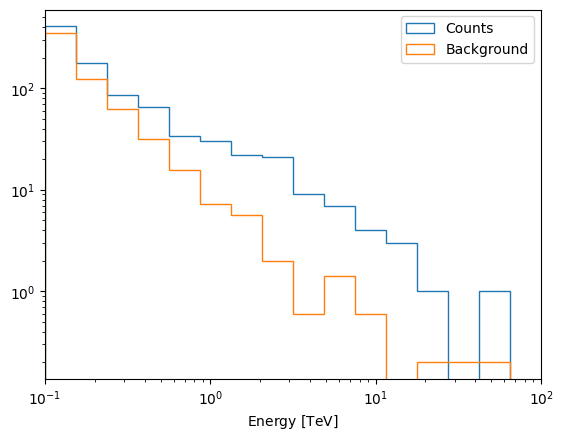

In [10]:
dataset_on_off.plot_counts()

### Fitting the spectrum

Here we create a copy of the initial spectrum to keep track of the ``true`` model.

In [11]:
model_fit = model_true.copy()
dataset_on_off.models = model_fit

In [12]:
results = Fit().run(datasets=dataset_on_off)
print(results)

OptimizeResult

	backend    : minuit
	method     : migrad
	success    : True
	message    : Optimization terminated successfully.
	nfev       : 62
	total stat : 8.91

CovarianceResult

	backend    : minuit
	method     : hesse
	success    : True
	message    : Hesse terminated successfully.



In [13]:
results.models

In [14]:
param = dataset_on_off.models.parameters[3]
Fit().confidence(datasets=[dataset_on_off], parameter=param, sigma=3, reoptimize=True)

{'success': True,
 'message': 'Minos terminated successfully.',
 'errp': np.float64(0.19156087657329632),
 'errn': np.float64(0.04064501923368657),
 'nfev': 150}

In [15]:
names = dataset_on_off.models.parameters_unique_names 
params = dataset_on_off.models.parameters
idx_free = [i for i, par in enumerate(params) if not par.frozen]

params[0].scan_values = np.linspace(1.8, 2.5, 20)
params[1].scan_values = np.linspace(1.5e-12, 3.5e-12, 20)
params[3].scan_values = np.linspace(0.00, 0.25, 20)

profiles_dict = {}

for i, idx in enumerate(idx_free):
    par = params[idx]
    par_name = names[idx]
    
    profile = Fit().stat_profile(datasets=[dataset_on_off],parameter=par, reoptimize=True)
    profile["stat_scan"] -= results.total_stat  # to have minimum at 0
    profiles_dict[par_name] = profile


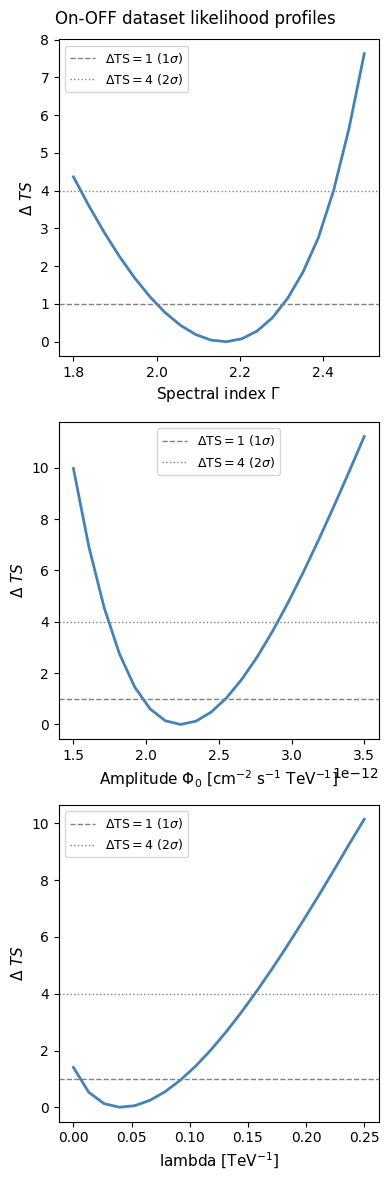

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(4, 12))

labels = [r"Spectral index $\Gamma$", r"Amplitude $\Phi_0$ [cm$^{-2}$ s$^{-1}$ TeV$^{-1}$]", r"lambda [TeV$^{-1}$]"]

for i, key in enumerate(profiles_dict.keys()):
    ax = axes[i]
    par_name = key
    label=labels[i]

    profile = profiles_dict[key]
    par_values = profile[f"{key}_scan"]
    stat_values = profile["stat_scan"] 

    ax.plot(par_values, stat_values, color="steelblue", lw=2)
    ax.axhline(1.0, color="gray", ls="--", lw=1, label=r"$\Delta\mathrm{TS}=1$ (1$\sigma$)")
    ax.axhline(4.0, color="gray", ls=":", lw=1, label=r"$\Delta\mathrm{TS}=4$ (2$\sigma$)")
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel(r"$\Delta\ TS$", fontsize=11)
    ax.legend(fontsize=9)

plt.suptitle("On-OFF dataset likelihood profiles", fontsize=12)
plt.tight_layout()
plt.show()

## What about flux points?

We can apply the usual recipe to determine the flux point measurement.

### Flux estimators (recap)

Most estimators produce flux estimates.

They run on bins of **reconstructed energy**. 

- The estimator does not modify the binning of the parent dataset, only group the energy bins.
- The requested edges are used to group the parent dataset energy edges into large bins.
- Therefore, the input energy edges are not always the same as the output energy bins provided in the final product.

In each bin, the estimator will determine the flux normalization factor, by performing a fit comparing predicted number of counts in the reference model to observed ones. Hence, the flux value in bin $i$ is:

$$ \Phi_i = k_i\, \Phi_{ref}(E_i)$$

Errors (from covariance or profile), upper limits and scan (e.g. log-likelihood) profiles are obtained for each of the $k_i$. The corresponding $\Phi_i$ are obtained by mutliplying by the reference flux (in the appropriate units, e.g. 'dnde', or 'flux') in bin $i$.

In [17]:
fpe = FluxPointsEstimator(energy_edges=energy_axis.edges, selection_optional=["errn-errp", "ul"], n_sigma_ul=2)

source_fp = fpe.run([dataset_on_off])

(2e-13, 2e-11)

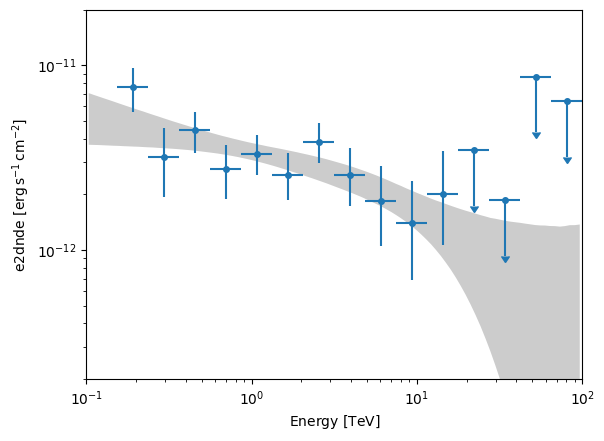

In [31]:
ax=source_fp.plot(sed_type="e2dnde")
ax=results.models[0].spectral_model.plot_error(sed_type="e2dnde", energy_bounds=[0.1,100]*u.TeV, ax=ax)
ax.set_ylim(2e-13,2e-11)

## Determining expected distribution of fitted parameters

Determining the expected range of fitted parameters can be important in a number of situations:
- in order to evaluate the feasibility of an observation for a given assumed model
- to understand whether your fitted parameters are expected in a given context 

### The Asimov dataset

An Asimov dataset is constructed by replacing the observed counts with the exact expected prediction from the model.


In [19]:
dataset.models = model_true
npred_on = dataset.npred()   # signal + background for SpectrumDataset
npred_off = dataset.background/alpha
asimov_ds = dataset_on_off.copy(name="asimov")
asimov_ds.counts=npred_on
asimov_ds.counts_off=npred_off

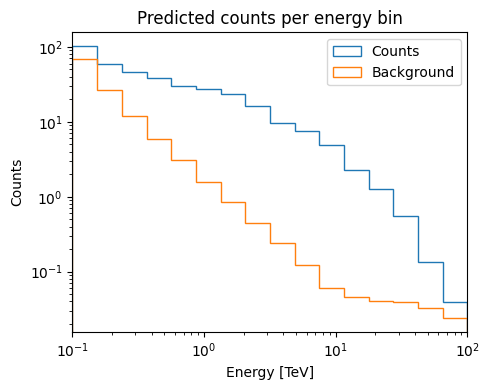

In [20]:
fig, ax = plt.subplots(figsize=(5, 4))
asimov_ds.plot_counts(ax=ax)
ax.set_title("Predicted counts per energy bin")
ax.set_xlabel("Energy [TeV]")
ax.set_ylabel("Counts")
plt.tight_layout()
plt.show()

### Fitting the Asimov dataset to get the extected distribution

We can now fit the asimov dataset. The fitter will converge quickly (the Asimov dataset has no noise), and the returned errors will be the Cramér–Rao bound.

The parameter errors on the Asimov dataset are equal to the
Cramér–Rao bound — the minimum variance achievable by any unbiased
estimator — by construction. This is asymptotically exact for Poisson
likelihoods (cash) but only approximate near the detection threshold
or for very few counts per bin. 

In [21]:
asimov_ds.models = model_true.copy()

In [35]:
result_asimov = Fit().run(datasets=asimov_ds)

In [39]:
def parameter_summary(fit_result):
    spectral_model = fit_result.models[0].spectral_model
    index = spectral_model.index.value
    amplitude = spectral_model_asimov.amplitude.value
    lambda_ = spectral_model.lambda_.value

    index_error = spectral_model.index.error
    amplitude_error = spectral_model.amplitude.error
    lambda_error = spectral_model.lambda_.error
    print(f"Gamma = {index:.2f} +/- {index_error:.3f}")
    print(f"Phi_0 = {amplitude:.2e} +/- {amplitude_error:.2e}")
    print(f"lambda = {lambda_:.2e} +/- {lambda_error:.2e}")

print(f"\nFitted parameters and errors:")
parameter_summary(results)

print(f"\nAsimov (Cramér–Rao bound) errors:")
parameter_summary(result_asimov)


Fitted parameters and errors:
Gamma = 2.16 +/- 0.154
Phi_0 = 2.50e-12 +/- 2.87e-13
lambda = 4.17e-02 +/- 4.55e-02

Asimov (Cramér–Rao bound) errors:
Gamma = 2.10 +/- 0.105
Phi_0 = 2.50e-12 +/- 2.58e-13
lambda = 5.00e-02 +/- 3.39e-02


### Parameter distribution validation — Monte Carlo ensemble
We now validate the Asimov errors by running Poisson realisations of the same observation. For each realisation we:

- Draw counts from a Poisson distribution with mean equal to the model prediction.
- Fit the spectral model and record the best-fit parameter values.

The standard deviation of the resulting distribution is the empirical estimate of the statistical uncertainty. In the asymptotic limit, it should match the Asimov interval for the parameter values considered here.

In [40]:
# First some plotting functions

def plot_hist_with_quantiles(ax, par_array, bins=20, color="b", alpha=0.6, q=[16, 84]):
    _=ax.hist(par_array, bins=bins, alpha=alpha, )
    vmin, vmax = np.percentile(par_array, q)
    ax.axvline(vmin, color=color, ls="--", lw=1.5,label="68% quantiles")
    ax.axvline(vmax, color=color, ls="--", lw=1.5)
    return ax
    
def compute_plot_asymetric_errors(param, asim_ds, ax, color="red"):
    conf = Fit().confidence(datasets=[asim_ds],parameter=param)
    max_val = conf["errp"]+param.value
    min_val = -conf["errn"]+param.value

    ax.axvline(min_val, color=color, ls=":", lw=1.5,label=r"1 $\sigma$ - Asimov")
    ax.axvline(max_val, color=color, ls=":", lw=1.5)
    return ax
    

In [41]:
import warnings
warnings.filterwarnings('ignore')

N_MC=1000 

results_on_off = []
for i in range(N_MC):
    # Clone dataset and draw a Poisson realisation
    ds = dataset_on_off.copy(name=f"mc-{i}")
    ds.models = model_true
    ds.fake(dataset.npred_background())

    # Copy True model
    ds.models = model_true.copy()

    result_mc = Fit().run([ds])
    results_on_off.append(result_mc)

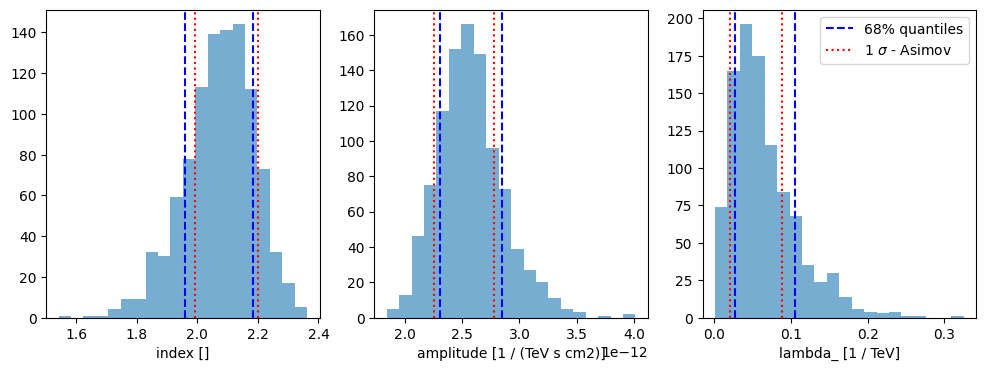

In [42]:
params = asimov_ds.models.parameters.free_parameters

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, param in zip(axes, params): 
    par_array = np.array([_.models[0].parameters[param.name].value for _ in results_on_off])
    _=plot_hist_with_quantiles(ax, par_array)
    _=compute_plot_asymetric_errors(param, asimov_ds,ax)
    ax.set_xlabel(f"{param.name} [{param.unit}]")
    plt.legend()

## Determining the expected distribution of flux points

Similarly we can use the Asimov dataset as a way to extract expected median value for the flux points or their upper limits.

To do so we apply the FluxPointsEstimator to the Asimov dataset itself.

In [43]:
asimov_fp = fpe.run([asimov_ds])

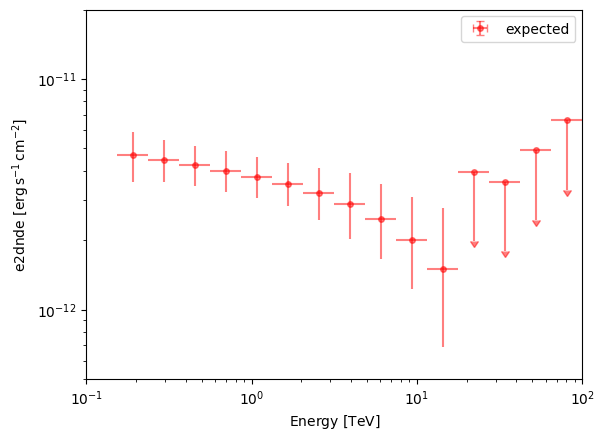

In [44]:
ax=asimov_fp.plot(sed_type="e2dnde", color='r', alpha=0.5, label="expected")
ax.set_ylim(5e-13,2e-11)
plt.legend()

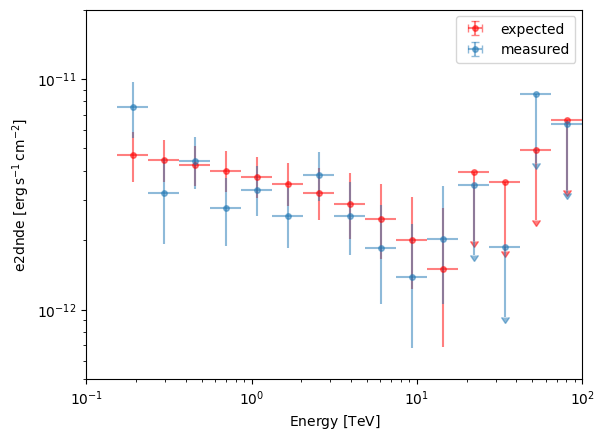

In [45]:
ax=asimov_fp.plot(sed_type="e2dnde", color='r', alpha=0.5, label="expected")
ax=source_fp.plot(sed_type="e2dnde", ax=ax, alpha=0.5, label="measured")
#ax=result_asimov.models[0].spectral_model.plot_error(sed_type="e2dnde", energy_bounds=[0.1,100]*u.TeV, ax=ax)
ax.set_ylim(5e-13,2e-11)
plt.legend()

### What would be the upper limits in the absence of signal

We can also extract the distributions of U.L. on every flux point assuming there is no signal (the exclusion sensitivity).

One can obtain them using toy model MC simulations or using the Asimov dataset in the asymptotic limit. Let's try this last approach.

In [46]:
asimov_ds.counts = dataset.background # i.e. no expected signal counts

fpe_ul = FluxPointsEstimator(energy_edges=energy_axis.edges, 
                             selection_optional=["ul"], 
                             n_sigma_ul=2
                            )
fp_ul_median = fpe_ul.run([asimov_ds])

# We change the n_sigma by +/-1 to obtain the 1 sigma range of expected ULs 
fpe_ul.n_sigma_ul=3
fp_ul_max = fpe_ul.run([asimov_ds])
fpe_ul.n_sigma_ul=1
fp_ul_min = fpe_ul.run([asimov_ds])


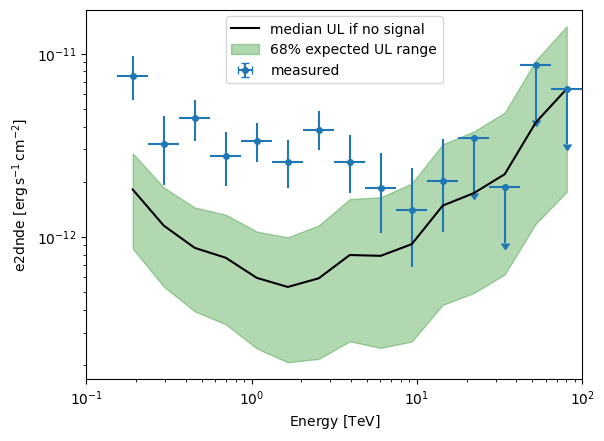

In [47]:
ax=source_fp.plot(sed_type="e2dnde", label="measured")

ax.plot(fp_ul_median.energy_ref, fp_ul_median.e2dnde_ul.quantity.squeeze(), 
        color='k', label="median UL if no signal")

ax.fill_between(fp_ul_median.energy_ref, 
                fp_ul_max.e2dnde_ul.quantity.squeeze(), 
                fp_ul_min.e2dnde_ul.quantity.squeeze(),
                color="green", alpha=0.3, label="68% expected UL range"
)
plt.legend()

### Validating flux points distribution with Monte Carlo ensemble
We now validate the expected flux points distribution by running the FluxPointsEstimator on Poisson realisations of the same observation. For each realisation we:

- Draw counts from a Poisson distribution with mean equal to the model prediction.
- Run the FluxPointsEstimator on the result

In the asymptotic limit, the MC distribution should match the Asimov interval for the flux points values.

Note that here we need to run the FluxPointsEstimator, which is a slower process. The simple for-loop above might too slow. Instead we will perform multi-processing simulations.

In [53]:
import warnings
warnings.filterwarnings('ignore')

N_MC=10

fp_simul = []
for i in range(N_MC):
    fp = fake_and_run_flux_points_estimation(dataset_on_off, model_true)
    fp_simul.append(fp)

In [128]:
from utils import fake_and_run_flux_points_estimation
from gammapy.utils.parallel import run_multiprocessing, multiprocessing_manager

def perform_fpe_simulation(nsim, dataset, background, model):
    indices = np.arange(nsim)

    inputs = [(dataset, background, model)  for _ in indices]

    fps = run_multiprocessing(fake_and_run_flux_points_estimation, inputs, task_name="simulation")

    axis = LabelMapAxis(indices, name='index')
    result = FluxPoints.from_stack(
                maps=fps,
                axis=axis,
            )
    return result

In [129]:
N_MC=1000
with multiprocessing_manager(backend="multiprocessing", pool_kwargs=dict(processes=4)):
    result = perform_fpe_simulation(N_MC, dataset_on_off, dataset.npred_background(), model_true)


(5e-13, 2e-11)

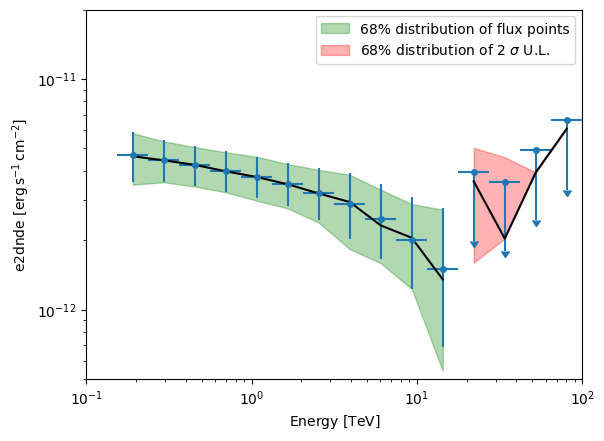

In [130]:
quantiles = np.quantile(result.e2dnde.quantity, [0.16, 0.5, 0.84], axis=0)
quantiles_ul = np.quantile(result.e2dnde_ul.quantity, [0.16, 0.5, 0.84], axis=0)

mask = asimov_fp.is_ul.data
ax = asimov_fp.plot(sed_type="e2dnde")
ax.loglog(result.energy_ref[~mask.squeeze()], quantiles[1,:][~mask], color="k")
ax.fill_between(result.energy_ref[~mask.squeeze()], 
                quantiles[2,:][~mask], 
                quantiles[0,:][~mask], color="g", alpha=0.3,
                label=r"68% distribution of flux points"
               )

ax.loglog(result.energy_ref[mask.squeeze()], quantiles_ul[1,:][mask], color="k")
ax.fill_between(result.energy_ref[mask.squeeze()], 
                quantiles_ul[2,:][mask], 
                quantiles_ul[0,:][mask], color="r", alpha=0.3,
                label=r"68% distribution of 2 $\sigma$ U.L."
               )

plt.legend()
ax.set_ylim(5e-13,2e-11)

## Determining the sensitivity to a spectral cutoff

Our dataset can apparently only marginaly detect the cutoff. We can try to measure the sensitivity to the cutoff by determining the minimal cutoff value yielding a 3$\sigma$ detection assuming the other model parameters stay the same.

To do so, we can scan the range of possible value and determine graphically or numerically the required value.

We will increase the source flux to make sure a detection is possible.

In [131]:
model_true.spectral_model.amplitude.value *=1.5

In [132]:
def asimov_dataset(dataset, alpha=0.2):
    """Return ON-OFF spectral dataset for the input model based on the input SpectrumDataset and alpha."""
    ds_on_off = SpectrumDatasetOnOff.from_spectrum_dataset(
                dataset=dataset,
                acceptance=1,
                acceptance_off=1 / alpha,
            )
    npred_on = dataset.npred()   # signal + background for SpectrumDataset
    npred_off = dataset.background/alpha
    ds_on_off.counts=npred_on
    ds_on_off.counts_off=npred_off
    return ds_on_off

In [133]:
lambda_values = np.geomspace(1e-2, 0.2, 20)

lambda_scan = []

for lambda_val in lambda_values:
    model_true.spectral_model.lambda_.value = lambda_val
    asimov_ds = asimov_dataset(dataset)

    fit_model = model_true.copy()
    asimov_ds.models = fit_model
    param = fit_model.spectral_model.lambda_
    result = select_nested_models(Datasets([asimov_ds]),[param], null_values=[0.])
    lambda_scan.append(result)

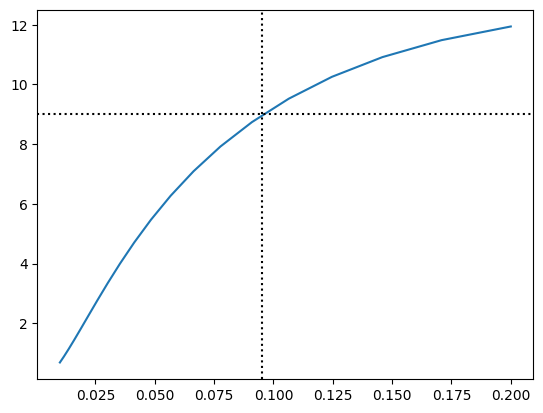

In [134]:
total_stats = [_["ts"] for _ in lambda_scan]

plt.plot(lambda_values, total_stats)
plt.axhline(9, color='k', linestyle=":")
plt.axvline(0.095, color='k', linestyle=":")